In [1]:
import pandas as pd
import numpy as np
import pyreadstat

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from fairlearn.metrics import MetricFrame, demographic_parity_difference, equalized_odds_difference

print("--- STEP 1: DATA LOADING & SCOPING ---")
file_path = r"E:\Waste of Time\IAIR7EDT (1)\IAIR7EFL.DTA"
cols = ['v005', 'v012', 'v025', 'v106', 's116', 'v190', 'm15_1']
df, meta = pyreadstat.read_dta(file_path, usecols=cols)

# Filter for women who had a birth in the recent window (drop NaNs and code 99)
df_clean = df.dropna(subset=['m15_1']).copy()
df_clean = df_clean[df_clean['m15_1'] != 99]

# Construct Binary Target: 1 = Institutional Delivery (Facility codes 20-33), 0 = Home/Other
df_clean['institutional_delivery'] = df_clean['m15_1'].apply(lambda x: 1 if 20 <= x <= 33 else 0)
print(f"Total analyzed records (women with recent births): {df_clean.shape[0]}")

print("\n--- STEP 2: PREPROCESSING & FEATURE ENGINEERING ---")
X = df_clean[['v012', 'v025', 'v106', 's116', 'v190']].copy()
y = df_clean['institutional_delivery']

# Impute missing values (Median for numerical Age, Mode for categorical)
X['v012'] = X['v012'].fillna(X['v012'].median())
for col in ['v025', 'v106', 's116', 'v190']:
    X[col] = X[col].fillna(X[col].mode()[0])

# Encode Place of Residence (1=Urban, 2=Rural -> 0=Urban, 1=Rural)
X['v025'] = X['v025'].replace({1: 0, 2: 1})

# One-Hot Encode Caste/Tribe (s116)
X = pd.get_dummies(X, columns=['s116'], drop_first=True)

print("\n--- STEP 3: TRAIN-TEST SPLIT & SMOTE RESAMPLING ---")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Apply SMOTE exclusively to the training split
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Training set balanced via SMOTE. Shape: {X_train_smote.shape}")
print(f"Untouched Test set size: {X_test.shape[0]} records")

print("\n--- STEP 4: TRAINING & EVALUATING CLASSIFICATION MODELS ---")
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

evaluation_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_prob)
    
    evaluation_results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })
    trained_models[name] = model

results_df = pd.DataFrame(evaluation_results)
print("\nComparative Performance Summary:")
print(results_df.to_string(index=False))

print("\n--- STEP 5: ALGORITHMIC FAIRNESS AUDIT (FAIRLEARN) ---")
# Map caste codes for interpretable subgroup analysis
caste_map = {1: 'Scheduled Caste', 2: 'Scheduled Tribe', 3: 'OBC', 4: 'General', 8: 'Don\'t Know'}
caste_test = df_clean.loc[X_test.index, 's116'].map(caste_map).fillna('Other/Unknown')

# Audit the Random Forest model (our primary non-linear classifier)
rf_pred = trained_models["Random Forest"].predict(X_test)

metric_frame = MetricFrame(
    metrics={
        'Accuracy': accuracy_score,
        'Recall': recall_score,
        'Precision': precision_score
    },
    y_true=y_test,
    y_pred=rf_pred,
    sensitive_features=caste_test
)

print("\nSubgroup Performance Breakdown (Random Forest):")
print(metric_frame.by_group)

dp_diff = demographic_parity_difference(y_test, rf_pred, sensitive_features=caste_test)
eo_diff = equalized_odds_difference(y_test, rf_pred, sensitive_features=caste_test)

print("\nFairness Disparity Metrics:")
print(f"Demographic Parity Difference: {dp_diff:.4f}")
print(f"Equalized Odds Difference: {eo_diff:.4f}")
print("\nPipeline execution complete! Ready for case study synthesis.")

ImportError: cannot import name '_safe_tags' from 'sklearn.utils._tags' (C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\utils\_tags.py)

In [7]:
!pip install --upgrade imbalanced-learn scikit-learn

   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/236.1 kB ? eta -:--:--
   ---------------------------------------  235.5/236.1 kB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 236.1/236.1 kB 3.6 MB/s eta 0:00:00
  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.12.3
    Uninstalling imbalanced-learn-0.12.3:
      Successfully uninstalled imbalanced-learn-0.12.3


In [1]:
!pip install --upgrade imbalanced-learn scikit-learn

In [3]:
import pandas as pd
import numpy as np
import pyreadstat

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from fairlearn.metrics import MetricFrame, demographic_parity_difference, equalized_odds_difference

print("--- STEP 1: DATA LOADING & SCOPING ---")
file_path = r"E:\Waste of Time\IAIR7EDT (1)\IAIR7EFL.DTA"
cols = ['v005', 'v012', 'v025', 'v106', 's116', 'v190', 'm15_1']
df, meta = pyreadstat.read_dta(file_path, usecols=cols)

# Filter for women who had a birth in the recent window (drop NaNs and code 99)
df_clean = df.dropna(subset=['m15_1']).copy()
df_clean = df_clean[df_clean['m15_1'] != 99]

# Construct Binary Target: 1 = Institutional Delivery (Facility codes 20-33), 0 = Home/Other
df_clean['institutional_delivery'] = df_clean['m15_1'].apply(lambda x: 1 if 20 <= x <= 33 else 0)
print(f"Total analyzed records (women with recent births): {df_clean.shape[0]}")

print("\n--- STEP 2: PREPROCESSING & FEATURE ENGINEERING ---")
X = df_clean[['v012', 'v025', 'v106', 's116', 'v190']].copy()
y = df_clean['institutional_delivery']

# Impute missing values (Median for numerical Age, Mode for categorical)
X['v012'] = X['v012'].fillna(X['v012'].median())
for col in ['v025', 'v106', 's116', 'v190']:
    X[col] = X[col].fillna(X[col].mode()[0])

# Encode Place of Residence (1=Urban, 2=Rural -> 0=Urban, 1=Rural)
X['v025'] = X['v025'].replace({1: 0, 2: 1})

# One-Hot Encode Caste/Tribe (s116)
X = pd.get_dummies(X, columns=['s116'], drop_first=True)

print("\n--- STEP 3: TRAIN-TEST SPLIT & SMOTE RESAMPLING ---")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Apply SMOTE exclusively to the training split
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Training set balanced via SMOTE. Shape: {X_train_smote.shape}")
print(f"Untouched Test set size: {X_test.shape[0]} records")

print("\n--- STEP 4: TRAINING & EVALUATING CLASSIFICATION MODELS ---")
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

evaluation_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_prob)
    
    evaluation_results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })
    trained_models[name] = model

results_df = pd.DataFrame(evaluation_results)
print("\nComparative Performance Summary:")
print(results_df.to_string(index=False))

print("\n--- STEP 5: ALGORITHMIC FAIRNESS AUDIT (FAIRLEARN) ---")
# Map caste codes for interpretable subgroup analysis
caste_map = {1: 'Scheduled Caste', 2: 'Scheduled Tribe', 3: 'OBC', 4: 'General', 8: 'Don\'t Know'}
caste_test = df_clean.loc[X_test.index, 's116'].map(caste_map).fillna('Other/Unknown')

# Audit the Random Forest model (our primary non-linear classifier)
rf_pred = trained_models["Random Forest"].predict(X_test)

metric_frame = MetricFrame(
    metrics={
        'Accuracy': accuracy_score,
        'Recall': recall_score,
        'Precision': precision_score
    },
    y_true=y_test,
    y_pred=rf_pred,
    sensitive_features=caste_test
)

print("\nSubgroup Performance Breakdown (Random Forest):")
print(metric_frame.by_group)

dp_diff = demographic_parity_difference(y_test, rf_pred, sensitive_features=caste_test)
eo_diff = equalized_odds_difference(y_test, rf_pred, sensitive_features=caste_test)

print("\nFairness Disparity Metrics:")
print(f"Demographic Parity Difference: {dp_diff:.4f}")
print(f"Equalized Odds Difference: {eo_diff:.4f}")
print("\nPipeline execution complete! Ready for case study synthesis.")

--- STEP 1: DATA LOADING & SCOPING ---
Total analyzed records (women with recent births): 176843

--- STEP 2: PREPROCESSING & FEATURE ENGINEERING ---


C:\Users\Hp\AppData\Local\Temp\ipykernel_22968\1767596010.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X[col] = X[col].fillna(X[col].mode()[0])



--- STEP 3: TRAIN-TEST SPLIT & SMOTE RESAMPLING ---
Training set balanced via SMOTE. Shape: (248370, 8)
Untouched Test set size: 35369 records

--- STEP 4: TRAINING & EVALUATING CLASSIFICATION MODELS ---

Comparative Performance Summary:
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.6701     0.9464  0.6617    0.7788   0.7589
      Decision Tree    0.6703     0.9443  0.6636    0.7794   0.7564
      Random Forest    0.6720     0.9449  0.6651    0.7807   0.7568

--- STEP 5: ALGORITHMIC FAIRNESS AUDIT (FAIRLEARN) ---

Subgroup Performance Breakdown (Random Forest):
                 Accuracy    Recall  Precision
s116                                          
Don't Know       0.802575  0.869565   0.904523
General          0.816407  0.845322   0.949351
OBC              0.728521  0.738631   0.953986
Other/Unknown    0.671642  0.679036   0.929590
Scheduled Caste  0.678459  0.679587   0.939705
Scheduled Tribe  0.440288  0.302840   0.912784

Fairnes

In [5]:
import pandas as pd
import numpy as np
import pyreadstat
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from fairlearn.metrics import MetricFrame, demographic_parity_difference, equalized_odds_difference

# ==========================================
# PHASE 1: DATA ACQUISITION & PREPARATION
# ==========================================
# Load NFHS-5 Microdata using Pyreadstat
file_path = r"E:\Waste of Time\IAIR7EDT (1)\IAIR7EFL.DTA"
cols = ['v005', 'v012', 'v025', 'v106', 's116', 'v190', 'm15_1']
df, meta = pyreadstat.read_dta(file_path, usecols=cols)

# Filter for women with a recent birth (drop NaNs and code 99)
df_clean = df.dropna(subset=['m15_1']).copy()
df_clean = df_clean[df_clean['m15_1'] != 99]

# Construct Target: 1 = Institutional Delivery (Codes 20-33), 0 = Home/Other
df_clean['institutional_delivery'] = df_clean['m15_1'].apply(lambda x: 1 if 20 <= x <= 33 else 0)

# ==========================================
# PHASE 2: FEATURE ENGINEERING
# ==========================================
X = df_clean[['v012', 'v025', 'v106', 's116', 'v190']].copy()
y = df_clean['institutional_delivery']

# Impute missing values
X['v012'] = X['v012'].fillna(X['v012'].median())
for col in ['v025', 'v106', 's116', 'v190']:
    X[col] = X[col].fillna(X[col].mode()[0])

# Encode Place of Residence (1=Urban, 2=Rural -> 0=Urban, 1=Rural)
X['v025'] = X['v025'].replace({1: 0, 2: 1})

# One-Hot Encode Caste/Tribe (s116)
X = pd.get_dummies(X, columns=['s116'], drop_first=True)

# ==========================================
# PHASE 3: SMOTE & TRAIN-TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Apply SMOTE exclusively to training data to prevent data leakage
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# ==========================================
# PHASE 4: MODEL TRAINING & EVALUATION
# ==========================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

evaluation_results = []
trained_models = {}

print("--- CLASSIFIER PERFORMANCE ON TEST SET ---")
for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    evaluation_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })
    trained_models[name] = model

print(pd.DataFrame(evaluation_results).to_string(index=False))

# ==========================================
# PHASE 5: ETHICAL FAIRNESS AUDIT
# ==========================================
# Map original caste codes for interpretable subgroup analysis
caste_map = {1: 'Scheduled Caste', 2: 'Scheduled Tribe', 3: 'OBC', 4: 'General', 8: 'Don\'t Know'}
caste_test = df_clean.loc[X_test.index, 's116'].map(caste_map).fillna('Other/Unknown')

# Audit the Random Forest model
rf_pred = trained_models["Random Forest"].predict(X_test)

metric_frame = MetricFrame(
    metrics={'Accuracy': accuracy_score, 'Recall': recall_score, 'Precision': precision_score},
    y_true=y_test,
    y_pred=rf_pred,
    sensitive_features=caste_test
)

print("\n--- SUBGROUP PERFORMANCE (RANDOM FOREST) ---")
print(metric_frame.by_group)

print("\n--- DISPARITY METRICS ---")
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test, rf_pred, sensitive_features=caste_test):.4f}")
print(f"Equalized Odds Difference: {equalized_odds_difference(y_test, rf_pred, sensitive_features=caste_test):.4f}")

C:\Users\Hp\AppData\Local\Temp\ipykernel_22968\2064869852.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X[col] = X[col].fillna(X[col].mode()[0])


--- CLASSIFIER PERFORMANCE ON TEST SET ---
              Model  Accuracy  Recall  ROC-AUC
Logistic Regression    0.6701  0.6617   0.7589
      Decision Tree    0.6703  0.6636   0.7564
      Random Forest    0.6720  0.6651   0.7568

--- SUBGROUP PERFORMANCE (RANDOM FOREST) ---
                 Accuracy    Recall  Precision
s116                                          
Don't Know       0.802575  0.869565   0.904523
General          0.816407  0.845322   0.949351
OBC              0.728521  0.738631   0.953986
Other/Unknown    0.671642  0.679036   0.929590
Scheduled Caste  0.678459  0.679587   0.939705
Scheduled Tribe  0.440288  0.302840   0.912784

--- DISPARITY METRICS ---
Demographic Parity Difference: 0.5983
Equalized Odds Difference: 0.6334


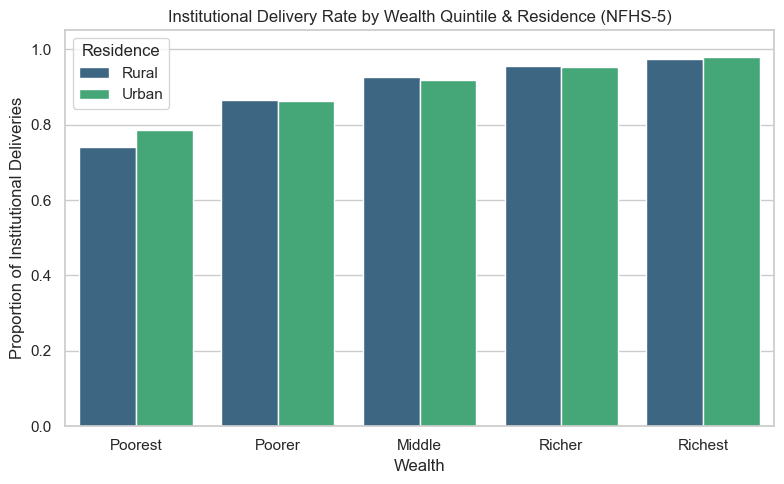

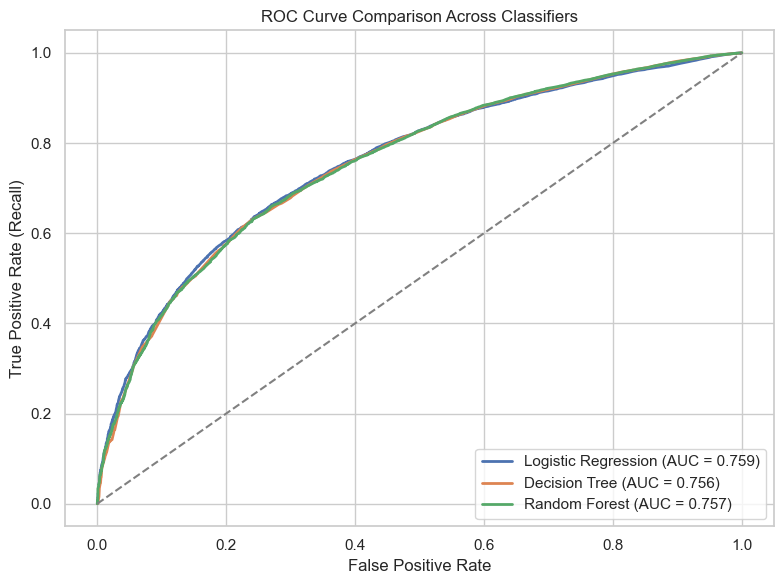

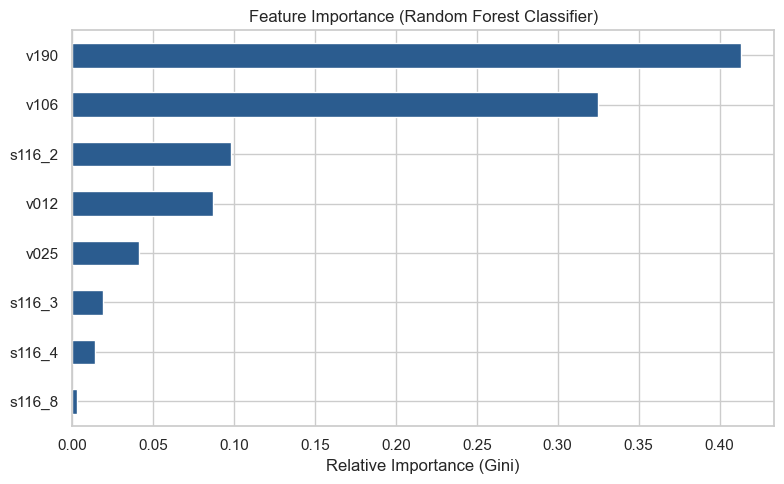

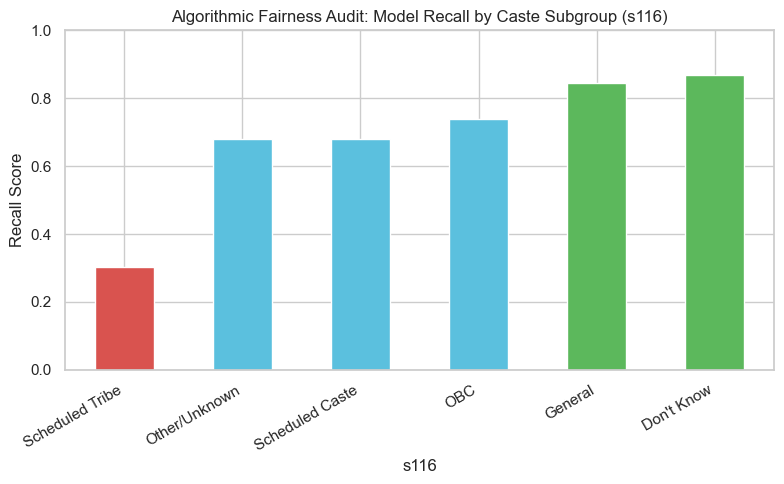

Confusion Matrix (Random Forest):
 [[ 3117  1205]
 [10397 20650]]


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix

sns.set_theme(style="whitegrid")

# 1. EDA Chart: Institutional Delivery Rate by Wealth Quintile & Residence
plt.figure(figsize=(8, 5))
eda_df = df_clean.copy()
eda_df['Wealth'] = eda_df['v190'].map({1: 'Poorest', 2: 'Poorer', 3: 'Middle', 4: 'Richer', 5: 'Richest'})
eda_df['Residence'] = eda_df['v025'].map({1: 'Urban', 2: 'Rural'})
sns.barplot(
    data=eda_df, x='Wealth', y='institutional_delivery', hue='Residence',
    order=['Poorest', 'Poorer', 'Middle', 'Richer', 'Richest'], palette='viridis', errorbar=None
)
plt.title('Institutional Delivery Rate by Wealth Quintile & Residence (NFHS-5)')
plt.ylabel('Proportion of Institutional Deliveries')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig('1_eda_wealth_access.png', dpi=300)
plt.show()

# 2. Comparative ROC-AUC Curves
plt.figure(figsize=(8, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_val:.3f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve Comparison Across Classifiers')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('2_roc_curves.png', dpi=300)
plt.show()

# 3. Random Forest Feature Importance
importances = pd.Series(trained_models["Random Forest"].feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#2b5c8f')
plt.title('Feature Importance (Random Forest Classifier)')
plt.xlabel('Relative Importance (Gini)')
plt.tight_layout()
plt.savefig('3_feature_importance.png', dpi=300)
plt.show()

# 4. Fairlearn Subgroup Recall Disparity Chart
plt.figure(figsize=(8, 5))
subgroup_recall = metric_frame.by_group['Recall'].sort_values()
colors = ['#d9534f' if val < 0.5 else '#5bc0de' if val < 0.75 else '#5cb85c' for val in subgroup_recall]
subgroup_recall.plot(kind='bar', color=colors)
plt.title('Algorithmic Fairness Audit: Model Recall by Caste Subgroup (s116)')
plt.ylabel('Recall Score')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1.0)
plt.tight_layout()
plt.savefig('4_fairness_recall.png', dpi=300)
plt.show()

print("Confusion Matrix (Random Forest):\n", confusion_matrix(y_test, rf_pred))